# Segmentation draft (v1)

The first version of splitting a plushie image into pieces, kept for reference. Code: `src/segmentation_draft.py`. The current version is `src/segmentation.py`.

**How v1 works**
1. **Line mask**: find thin, long, dark strokes (outlines). These act as *walls* between pieces.
2. **Color split**: smooth the image, then group pixels into 10 colors with k-means (in Lab color space).
3. **Regions**: connected blobs of one color that don't cross a wall.
4. **Merge**: tiny blobs join their nearest neighbor; touching regions with near-identical colors merge.
5. **Fill lines**: outline pixels are split between the pieces on either side.

**Known problems (fixed in the current version)**
- Every line is a wall, so facial features drawn as lines (mouths, closed eyes, "x" noses) disappear into the face.
- Tiny pieces always merge, even high-contrast ones like small black eyes.

**Columns below:** original cutout | detected lines | pieces (random color per piece) | pieces (real average color)

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_2D = ROOT / "data" / "test_images" / "2d"
sys.path.append(str(ROOT))

from src.background_removal import load_rgb, remove_background
from src.segmentation_draft import segment, colorize


def show(images, titles=None, size=4):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, t in zip(axes, images, titles or [""] * len(images)):
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
        ax.set_title(t)
        ax.axis("off")
    plt.show()


def show_pieces(rgba, regions):
    """Each piece filled with its real average color, with dark borders between pieces."""
    rgb = rgba[..., :3].astype(float)
    n = regions.max() + 1
    counts = np.bincount(regions.ravel(), minlength=n)
    means = np.stack([np.bincount(regions.ravel(), rgb[..., c].ravel(), n) for c in range(3)], 1)
    means = (means / np.maximum(counts, 1)[:, None]).astype(np.uint8)
    means[0] = 255
    out = means[regions]
    edges = cv2.morphologyEx(regions.astype(np.uint16), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    out[edges] = (40, 40, 40)
    return out

## Easy

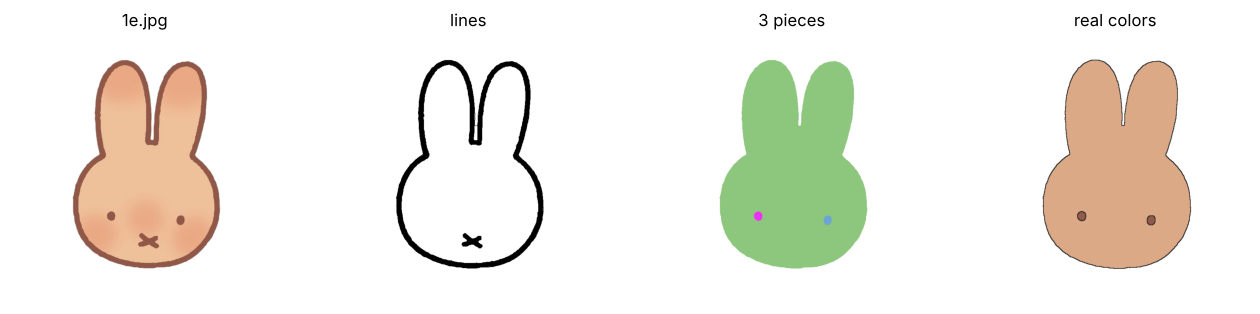

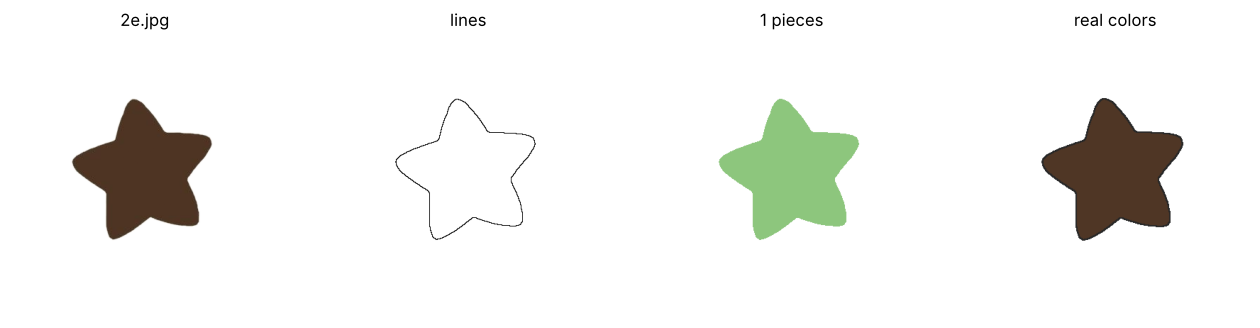

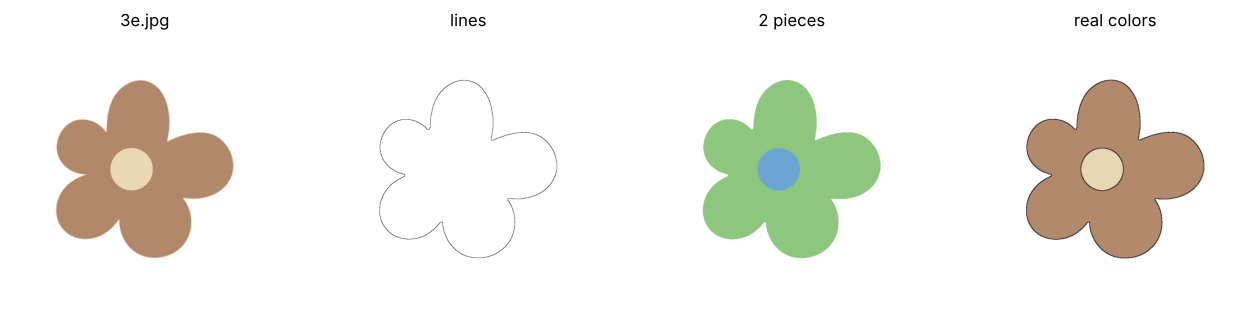

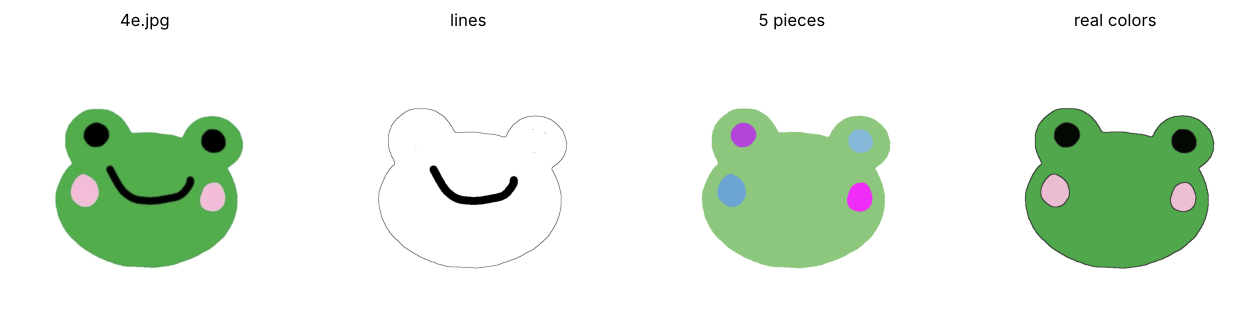

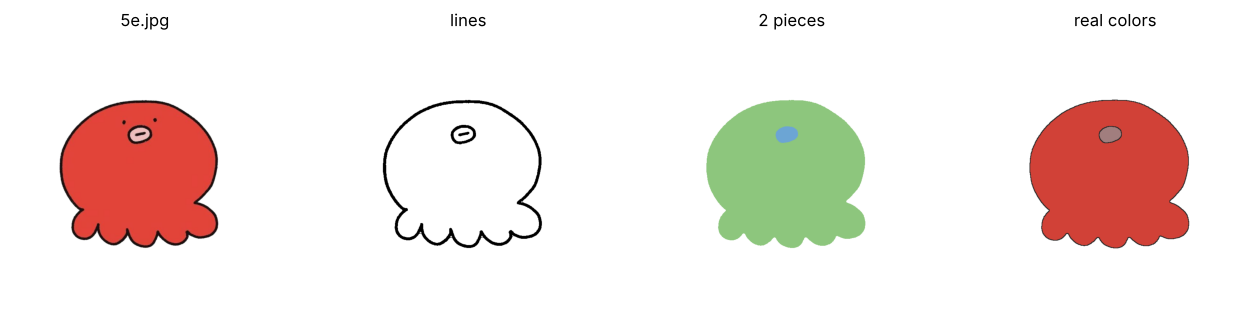

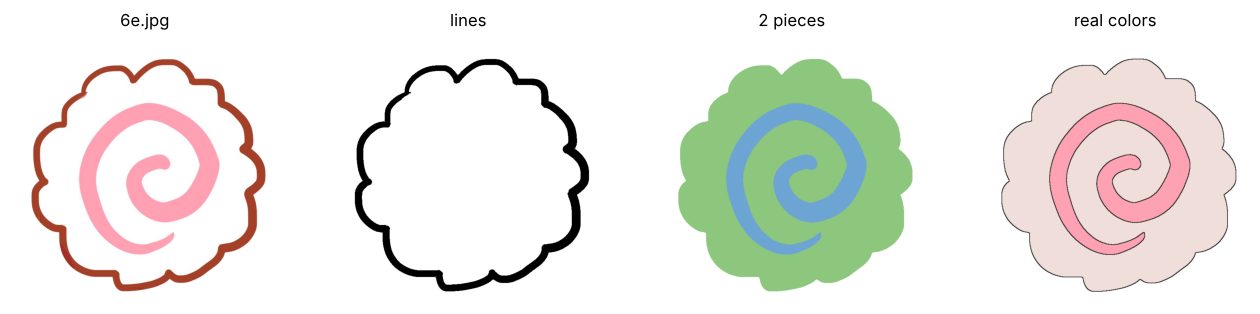

In [2]:
for path in sorted((DATA_2D / "easy").glob("*")):
    if path.suffix.lower() not in {".png", ".jpg", ".jpeg", ".webp"}:
        continue
    rgba, _ = remove_background(load_rgb(path, 768), use_ai_fallback=False)
    regions, lines = segment(rgba)
    show([rgba, ~lines, colorize(regions), show_pieces(rgba, regions)],
         [path.name, "lines", f"{regions.max()} pieces", "real colors"])

## Medium

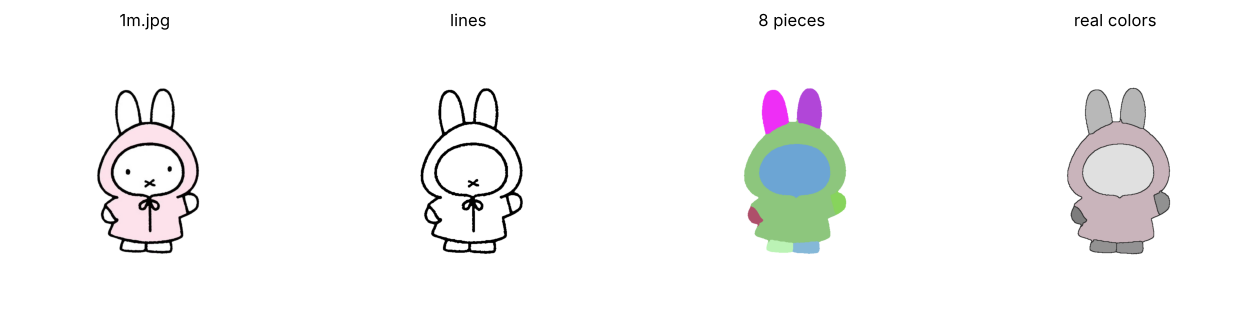

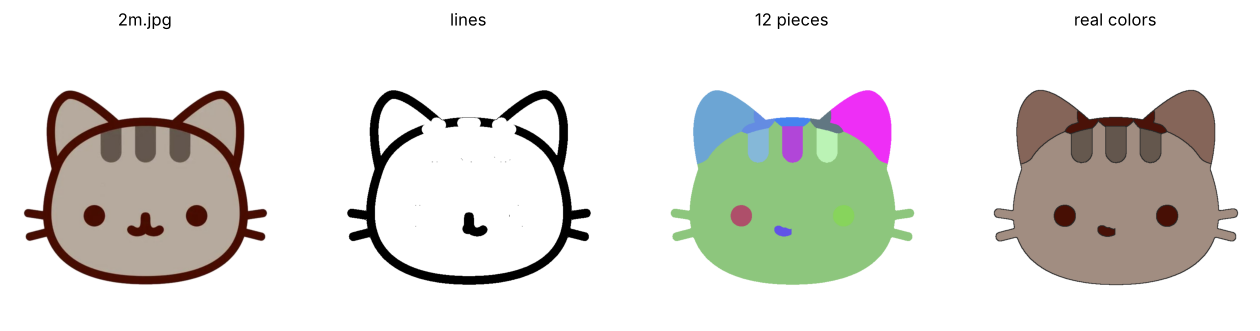

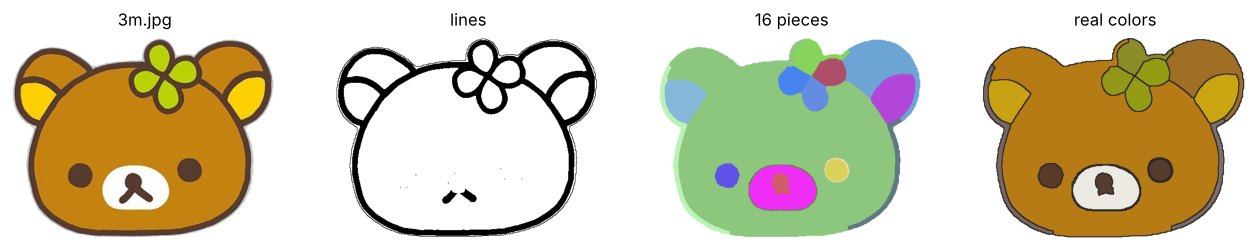

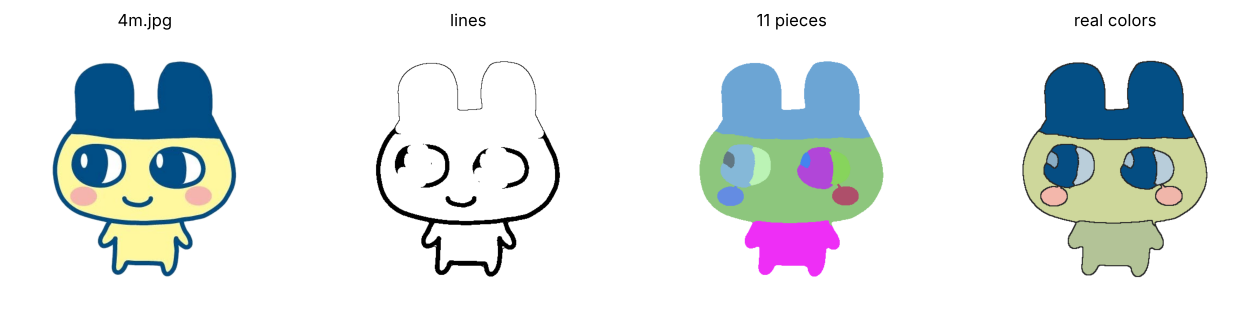

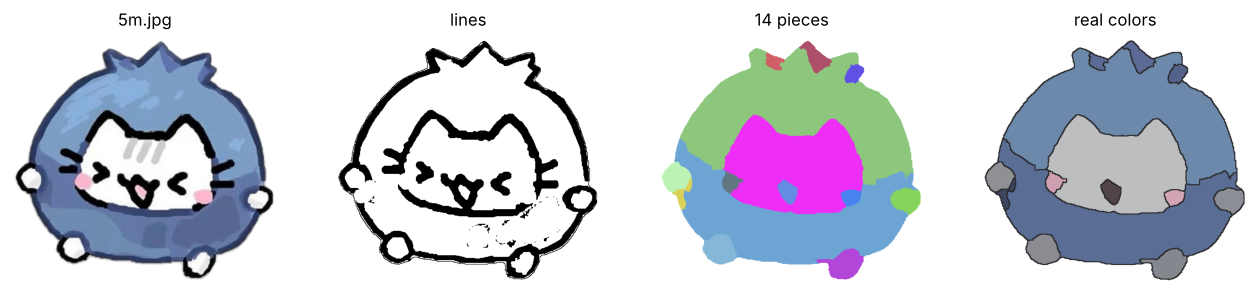

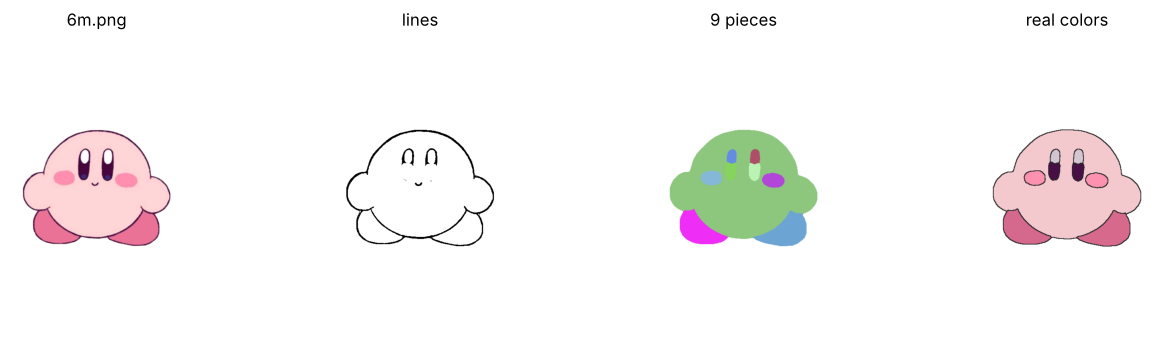

In [3]:
for path in sorted((DATA_2D / "medium").glob("*")):
    if path.suffix.lower() not in {".png", ".jpg", ".jpeg", ".webp"}:
        continue
    rgba, _ = remove_background(load_rgb(path, 768), use_ai_fallback=False)
    regions, lines = segment(rgba)
    show([rgba, ~lines, colorize(regions), show_pieces(rgba, regions)],
         [path.name, "lines", f"{regions.max()} pieces", "real colors"])

## Hard

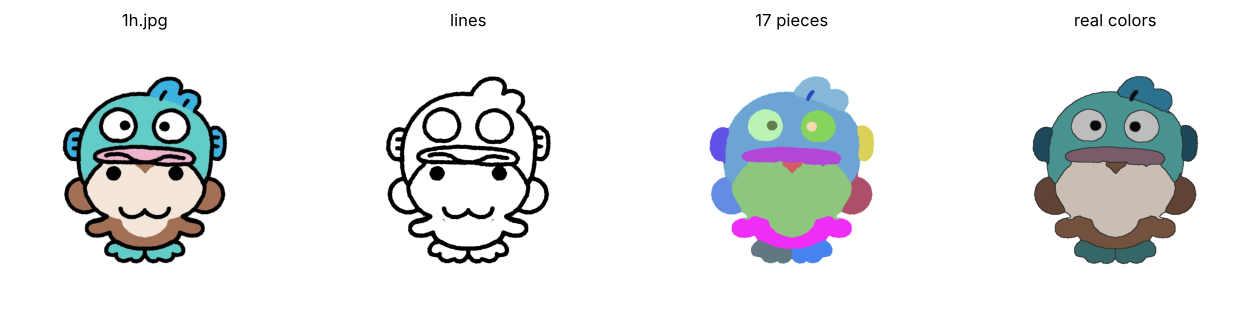

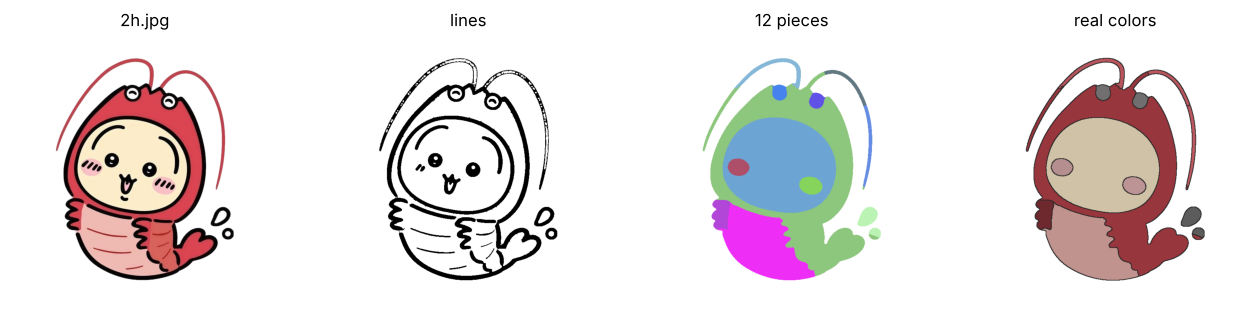

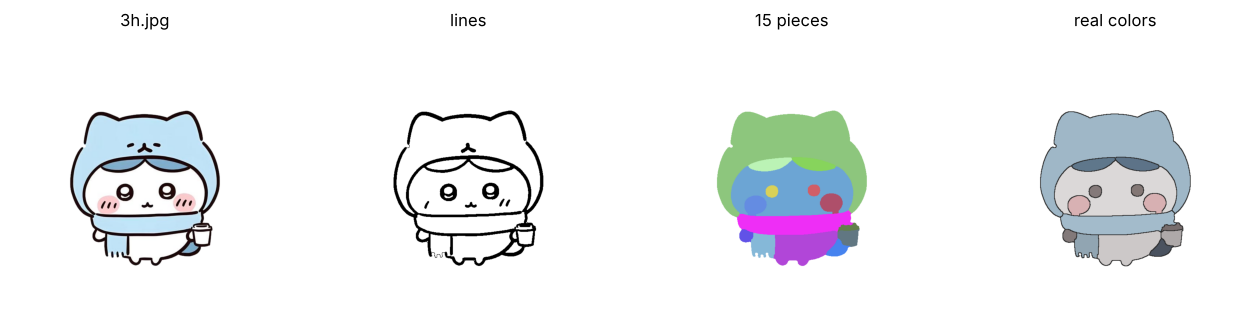

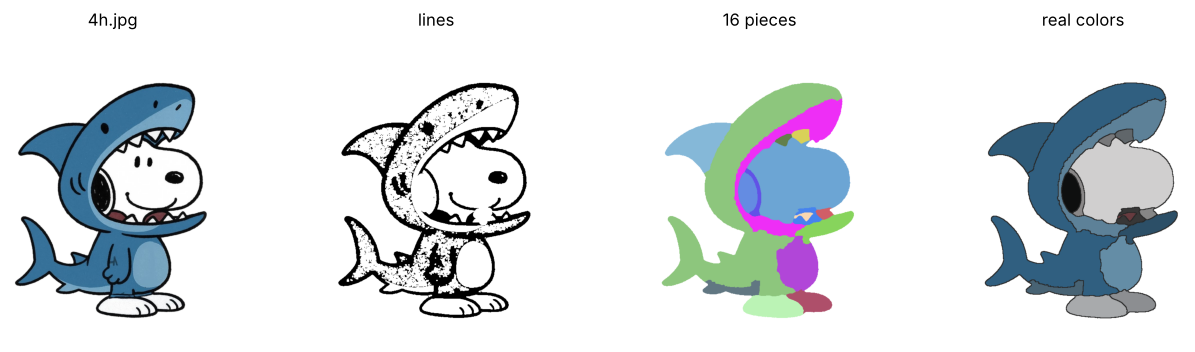

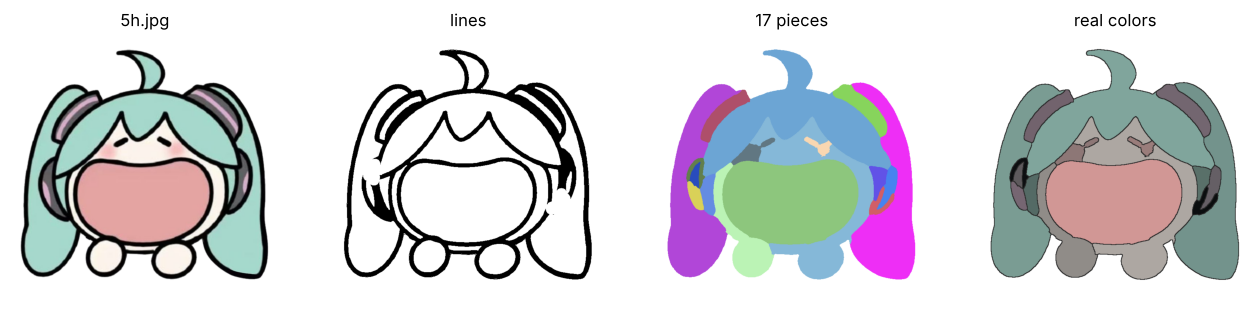

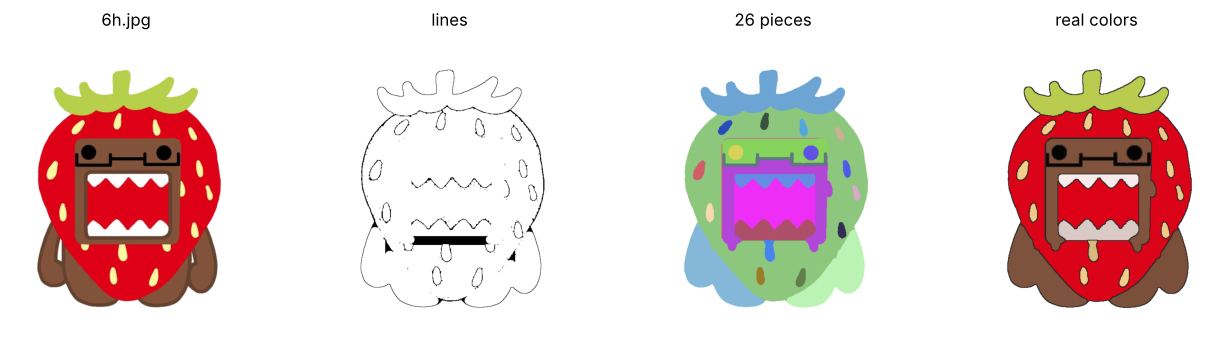

In [4]:
for path in sorted((DATA_2D / "hard").glob("*")):
    if path.suffix.lower() not in {".png", ".jpg", ".jpeg", ".webp"}:
        continue
    rgba, _ = remove_background(load_rgb(path, 768), use_ai_fallback=False)
    regions, lines = segment(rgba)
    show([rgba, ~lines, colorize(regions), show_pieces(rgba, regions)],
         [path.name, "lines", f"{regions.max()} pieces", "real colors"])